State telescope in use Draco2
How many points to take focus at? (input a positive integer > 3) 5
Save data? (Y/n) Y
Enter value [1] for FWHM: 5.52
Enter value [1] for focuser postion: 5676
Enter value [2] for FWHM: 3.67
Enter value [2] for focuser postion: 5536
Enter value [3] for FWHM: 2.03
Enter value [3] for focuser postion: 5196
Enter value [4] for FWHM: 4.19
Enter value [4] for focuser postion: 4856
Enter value [5] for FWHM: 12.01
Enter value [5] for focuser postion: 4516


Move the CCD to this this position: 5231.765776932645
The change in position from last inputted value is: 5219.755776932645
saving in current directory: /home/thomas/Documents/Durham/Astrolabs


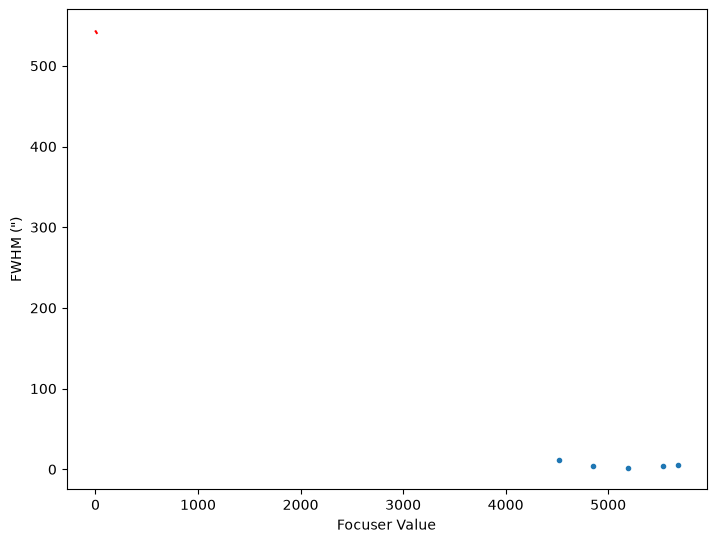

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize
import scipy.stats
import datetime as d
import os 



telescope = str(input("State telescope in use"))
points_in = int(input("How many points to take focus at? (input a positive integer > 3)"))

if points_in < 3:
    points = 3
else:
    points = points_in
save_status_in = str(input("Save data? (Y/n)"))

FWHM = np.zeros(points)
focuser_value = np.zeros(points)

if save_status_in == 'Y':
    save_status = True
elif save_status_in == 'y':
    save_status = True
elif save_status_in == 'yes':
    save_status = True
elif save_status_in == 'Yes':
    save_status = True
elif save_status_in == 'YES':
    save_status = True
else:
    save_status = False 


for i in range (0,points):
    
    focuser_value[i] = float(input("Enter value " + str([i + 1 ])+ " for FWHM:"))
    FWHM[i] = float(input("Enter value " + str([i + 1])+ " for focuser postion:"))

def focus(x, *params):
    return params[0]*x**2 + params[1]*x + params[2]

initial_values = [1,1,1]

popt, cov = scipy.optimize.curve_fit(focus, # function to fit
                                     FWHM, # x data
                                     focuser_value, # y data
                                     p0=initial_values, # starting point for fit
                                     check_finite=True) # raise ValueError if NaN encountered (don't allow errors to pass)

plt.figure(1).add_axes((0,0,1,1))
plt.errorbar(FWHM, 
             focuser_value,
             marker='.', 
             linestyle='None',
             alpha = 1)
plt.xlabel('Focuser Value') # Axis labels
plt.ylabel('FWHM (")')

smooth_x = np.linspace(min(focuser_value), max(focuser_value), 10000) # more points, over range of data
plt.plot(smooth_x, 
         focus(smooth_x , *popt), 
         color='r')

good_focus = -1*popt[1] / (2*popt[0])

print("Move the CCD to this this position: " + str(good_focus))
print("The change in position from last inputted value is: " + str(-1*focuser_value[-1] + good_focus))


time = d.datetime.now()
export_name = str(time) + "Focusing for " + telescope

export_data = np.array([focuser_value, FWHM])

if save_status == True:
    plt.savefig((export_name + " graph.png"), dpi = 100, bbox_inches = 'tight', format = 'png') 
    np.savetxt(export_name + " data", export_data)
    print('saving in current directory: ' + str(os.getcwd()))
    plt.show
else:
    plt.show()

In [38]:
%pip install datetime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [datetime]━━ 1/3 [zope.interface]
Note: you may need to restart the kernel to use updated packages.
